In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [3]:
df = pd.read_csv("../data/online_shoppers_intention.csv")
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [5]:
def check_df(dataframe, head=5):
    print('##################### Shape #####################')
    print(dataframe.shape)
    print('##################### Types #####################')
    print(dataframe.dtypes)
    print('##################### Duplicated #####################')
    print(dataframe.duplicated().sum())
    print('##################### Head #####################')
    print(dataframe.head(head))
    print('##################### Tail #####################')
    print(dataframe.tail(head))
    print('##################### NA #####################')
    print(dataframe.isnull().sum())
    print('##################### Quantiles #####################')
    print(dataframe.describe([0, 0.05, 0.50, 0.95, 0.99, 1]).T)

check_df(df)

##################### Shape #####################
(12330, 18)
##################### Types #####################
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                       bool
dtype: object
##################### Duplicated #####################
125
##################### Head #####################
   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1             

In [9]:
cat_cols = [
    "Month",
    "VisitorType",
    "Weekend",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType"
]

target = "Revenue"

num_cols = [
    col for col in df.columns
    if col not in cat_cols + [target]
]

print("Categorical:", cat_cols)
print("Numerical:", num_cols)

Categorical: ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
Numerical: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']


Soru : OperatingSystems, Browser ve Region sütunları sayılarla temsil ediliyor olabilir.

Bunlar gerçekten sürekli sayısal değişkenler mi, yoksa kategorik kodlar mı?

In [ ]:
#OperatingSystems, Browser ve Region sütunları sayısal değerlerle ifade edilse de kategorik (nominal) değişkenlerdir. Bu sayılar bir miktar veya büyüklük değil, farklı kategorileri temsil eder. Dolayısıyla aralarında matematiksel bir sıralama ilişkisi yoktur. 

Öncelikle Revenue değişkenimizin iki sınıfı var:
- True (1) → Satın alma gerçekleşmiş.
- False (0) → Satın alma gerçekleşmemiş.



In [17]:

print("######### Sınıf sayılarını hesaplama #############")
print(df["Revenue"].value_counts())

print("######### Sınıf yüzdesini hesaplama #############")
print(df["Revenue"].value_counts(normalize=True) * 100)

######### Sınıf sayılarını hesaplama #############
Revenue
False    10422
True      1908
Name: count, dtype: int64
######### Sınıf yüzdesini hesaplama #############
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


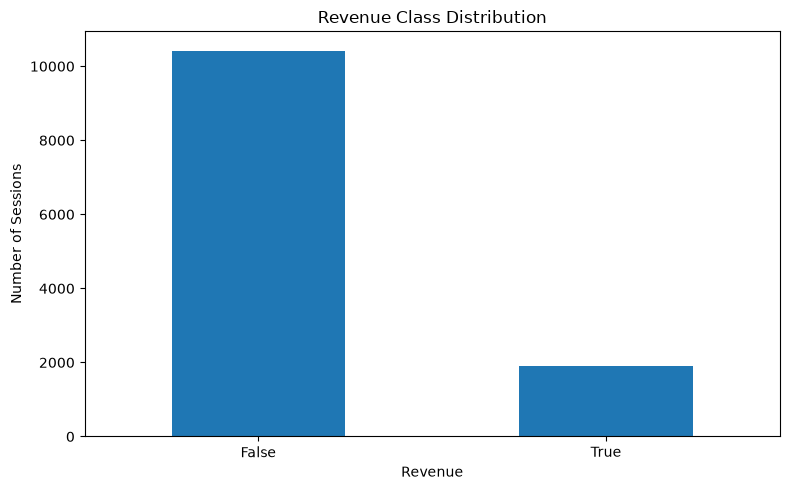

In [18]:
revenue_counts = df["Revenue"].value_counts()

plt.figure(figsize=(8,5))

revenue_counts.plot(kind="bar")
plt.title("Revenue Class Distribution")
plt.xlabel("Revenue")
plt.ylabel("Number of Sessions")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

### Soru

Bir model bütün ziyaretçiler için:
```
Revenue = False
```

tahmini yaparsa yaklaşık %84,5 Accuracy elde edebilir.

**Peki bu model gerçekten başarılı mıdır?**

Neden yalnızca Accuracy kullanmak istemediğimizi açıkla.




In [ ]:
#Accuracy, dengesiz veri setlerinde yanıltıcı olabilir. Çünkü model çoğunluk sınıfını sürekli tahmin ederek yüksek doğruluk elde edebilir. Bu örnekte model %84,5 Accuracy değerine ulaşsa da satın alma gerçekleştiren hiçbir müşteriyi doğru tahmin edemez.

In [21]:
visitor_analysis = (
    df.groupby("VisitorType")["Revenue"]
    .agg(["count", "sum", "mean"])
)

visitor_analysis["purchase_rate"] = (
    visitor_analysis["mean"] * 100
)

visitor_analysis

,count,sum,mean,purchase_rate
VisitorType,,,,
New_Visitor,1694,422,0.249115,24.911452
Other,85,16,0.188235,18.823529
Returning_Visitor,10551,1470,0.139323,13.932329


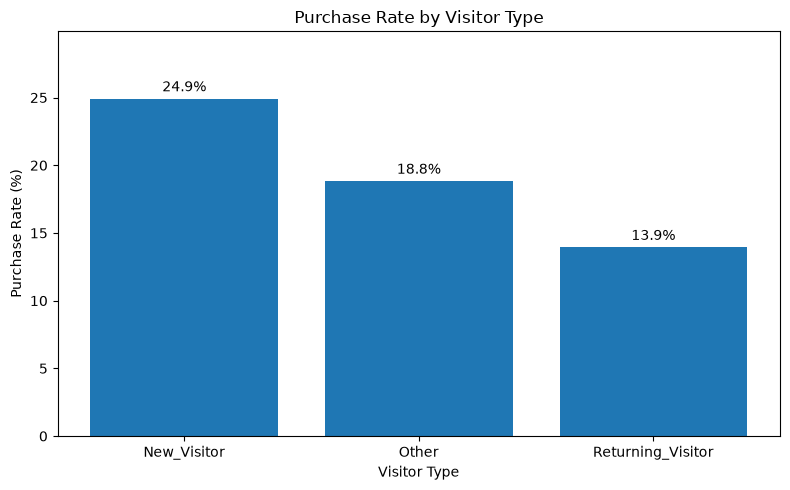

In [22]:
visitor_rates = visitor_analysis["purchase_rate"]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    visitor_rates.index,
    visitor_rates.values
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.title("Purchase Rate by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Purchase Rate (%)")

plt.ylim(0, max(visitor_rates.max() * 1.2, 1))

plt.tight_layout()
plt.show()

VisitorType analizinde, yeni ziyaretçilerin satın alma oranının daha yüksek olduğunu gözlemledim. Bu durum ziyaretçi türü ile satın alma davranışı arasında bir ilişki olabileceğini gösteriyor. Ancak tek başına nedensellik kanıtlamıyor.

In [23]:
weekend_analysis = (
    df.groupby("Weekend")["Revenue"]
    .agg(["count", "sum", "mean"])
)

weekend_analysis["purchase_rate"] = (
    weekend_analysis["mean"] * 100
)

weekend_analysis

,count,sum,mean,purchase_rate
Weekend,,,,
False,9462,1409,0.148911,14.891144
True,2868,499,0.173989,17.398884


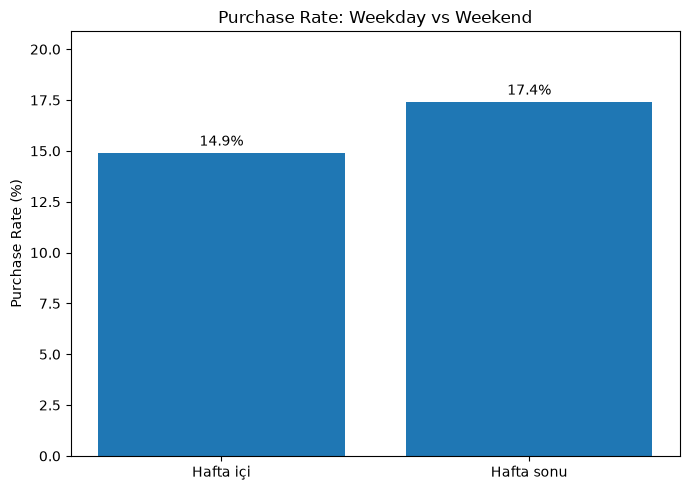

In [24]:
weekend_rates = weekend_analysis["purchase_rate"]

labels = ["Hafta içi", "Hafta sonu"]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    labels,
    [
        weekend_rates.get(False, 0),
        weekend_rates.get(True, 0)
    ]
)

plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.title("Purchase Rate: Weekday vs Weekend")
plt.ylabel("Purchase Rate (%)")

plt.ylim(0, max(weekend_rates.max() * 1.2, 1))

plt.tight_layout()
plt.show()

Hafta içi ve hafta sonu satın alma oranlarını karşılaştırdığımda hafta sonu biraz artış gözlemledim. Ancak iki grup arasındaki farkın anlamlı olup olmadığını değerlendirmek için daha fazla analiz yapılması gerekir.

In [27]:
month_analysis = (
    df.groupby("Month")["Revenue"]
    .agg(["count", "sum", "mean"])
)

month_analysis["purchase_rate"] = (
    month_analysis["mean"] * 100
)



month_analysis = month_analysis.dropna(
    subset=["purchase_rate"]
)

month_analysis

,count,sum,mean,purchase_rate
Month,,,,
Aug,433,76,0.175520,17.551963
Dec,1727,216,0.125072,12.507238
Feb,184,3,0.016304,1.630435
Jul,432,66,0.152778,15.277778
June,288,29,0.100694,10.069444
Mar,1907,192,0.100682,10.068170
May,3364,365,0.108502,10.850178
Nov,2998,760,0.253502,25.350233
Oct,549,115,0.209472,20.947177


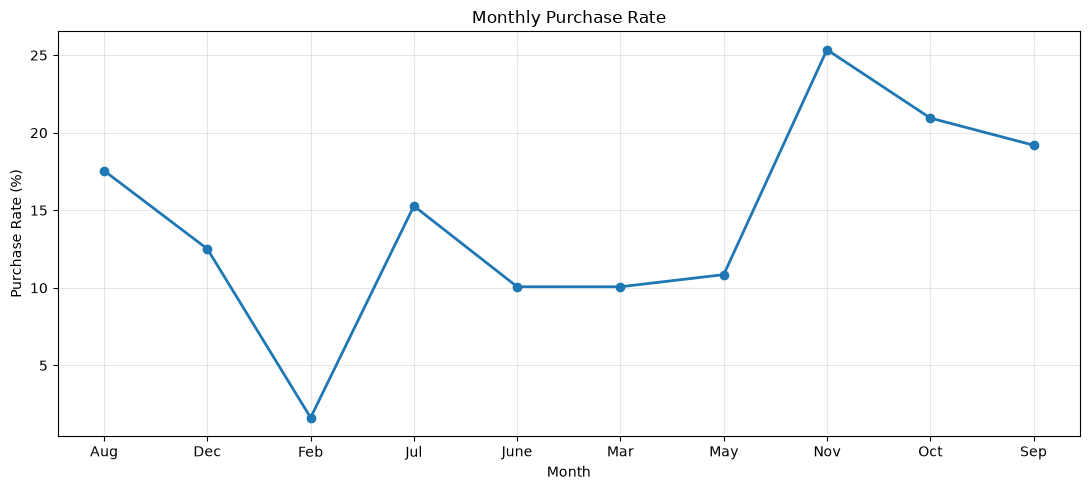

In [28]:
plt.figure(figsize=(11, 5))

plt.plot(
    month_analysis.index,
    month_analysis["purchase_rate"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Purchase Rate")
plt.xlabel("Month")
plt.ylabel("Purchase Rate (%)")

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Aylara göre satın alma oranlarının değiştiğini gözlemledim. En yüksek oran Kasım ayında, en düşük oran ise  Şubat ayında gerçekleşmiş. Bu durum mevsimsellik veya kampanya dönemleriyle ilişkili olabilir. Ancak yalnızca bu analizden kesin bir neden çıkaramayız.